# Designing and Analyzing an A/B Test for a Checkout Flow
**A/B Testing Design & Analysis — Portfolio Project (100% real data)**

Datasets:
1. **Udacity / e-commerce website A/B test** (real, 294,478 rows, `old_page` vs `new_page`, real user timestamps, plus `countries.csv` demographics) — the *primary* experiment: did the redesigned page raise purchase conversion at the top of the funnel feeding checkout?
2. **Cookie Cats mobile game A/B test** (real, 90,189 users, `gate_30` vs `gate_40`, D1/D7 retention + continuous `sum_gamerounds`) — the *secondary* experiment, reused to demonstrate **guardrail metrics** (D1 retention as a canary, gameplay depth as a continuous metric for Welch's t-test).

No simulated users anywhere. The only "simulation" in this project is the standard statistical machinery itself (normal-approximation power curves, Monte-Carlo peeking discussion) — clearly labeled as methods, never as data.



## 1. Business Problem & Hypothesis

**Business context.** An e-commerce company redesigned the page that sits at the top of the purchase funnel (everything between "land" and "checkout") to increase purchase conversion. Engineering spent weeks building it. Leadership asks a yes/no question: *"Did the new page convert better?"* — and, implicitly, *"is it worth shipping to 100% of traffic?"*

That question decomposes into three statistical sub-questions:

1. **Primary metric:** *Conversion rate* — % of users who purchase (convert) in the experiment window.
2. **Secondary / guardrail logic:** public e-commerce logs rarely ship AOV or load-time telemetry, so guardrail duty is demonstrated where real instrumentation exists — in the **Cookie Cats** experiment: D1 retention acts as a short-horizon canary that must not degrade while D7 (the primary retention metric) is judged, and gameplay depth (`sum_gamerounds`, continuous) exercises Welch's t-test machinery. The *method* transfers 1:1 to AOV/load-time in a company that logs them.
3. **Statistical machinery:** how much data do we need (power), is the answer real (significance), is the answer *big enough to matter* (practical significance), and can we trust the machinery at all (data hygiene / SRM / pitfalls).


In [1]:

from ab_stats import (run_power_analysis, power_curve,
                      check_srm, run_ztest, run_ttest, guardrail_verdict)
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams.update({"figure.dpi": 110, "axes.titlepad": 12})

# ---- The experiment spec — written down BEFORE analysis (pre-registration spirit)
EXPERIMENT = {
    "name": "ecommerce_page_redesign",
    "h0": "Conversion rate of the new page == conversion rate of the old page",
    "h1": "New page increases conversion (one-sided ship decision)",
    "primary_metric": "converted",
    "guardrails_for_cookie_cats": ["retention_1 (canary)", "sum_gamerounds (engagement depth)"],
    "alpha": 0.05,
    "power_target": 0.80,
    "baseline_rate": 0.1204,   # measured from this dataset's actual control rate
    "mde_pp": 1.0,             # minimum detectable effect worth caring about
}
print(json.dumps(EXPERIMENT, indent=2))


{
  "name": "ecommerce_page_redesign",
  "h0": "Conversion rate of the new page == conversion rate of the old page",
  "h1": "New page increases conversion (one-sided ship decision)",
  "primary_metric": "converted",
  "guardrails_for_cookie_cats": [
    "retention_1 (canary)",
    "sum_gamerounds (engagement depth)"
  ],
  "alpha": 0.05,
  "power_target": 0.8,
  "baseline_rate": 0.1204,
  "mde_pp": 1.0
}



**Hypotheses (defined before looking at any data):**

| | Statement |
|---|---|
| **H₀ (null)** | Conversion rate of the new page **equals** the old page: `p_new − p_old = 0` |
| **H₁ (alternative)** | New page **increases** conversion: `p_new − p_old > 0` (one-sided — we only *ship on improvement*) |

Why one-sided? A ship decision is directional: "significant but worse" won't ship anyway; the two-sided test burns extra sample size proving a direction we don't care about. We ALSO run the two-sided version as a robustness check (Section 5) — the interview-safe way to show both are on the table.

---

## 2. Power Analysis (Sample Size Calculation)

> **Why this step matters — the fresher's trap.** Running a test "until it looks significant" without a power calculation manufactures false negatives: genuinely working features get labelled as failures because the experiment never had the statistical muscle to detect their (real, small) effect. Power < 0.5 means noise wins more often than signal. The sample size is a *budget decision made before launch*.


In [2]:

# ---- Section 2a: required n per variant -------------------------------
result = run_power_analysis(
    baseline_rate=EXPERIMENT["baseline_rate"],
    mde_pp=EXPERIMENT["mde_pp"],
    alpha=EXPERIMENT["alpha"],
    power=EXPERIMENT["power_target"],
    alternative="larger",
)
print(f"Cohen's h (standardised effect)          : {result['cohen_h']:.4f}")
print(f"Required sample size PER VARIANT         : {result['n_per_variant']:,}")
print(f"Required TOTAL sample size               : {result['n_total']:,}")
print(f"Expected treatment rate for 1.0pp lift   : {result['treatment_rate_assumed']:.1%}")


Cohen's h (standardised effect)          : 0.0302
Required sample size PER VARIANT         : 13,557
Required TOTAL sample size               : 27,114
Expected treatment rate for 1.0pp lift   : 13.0%


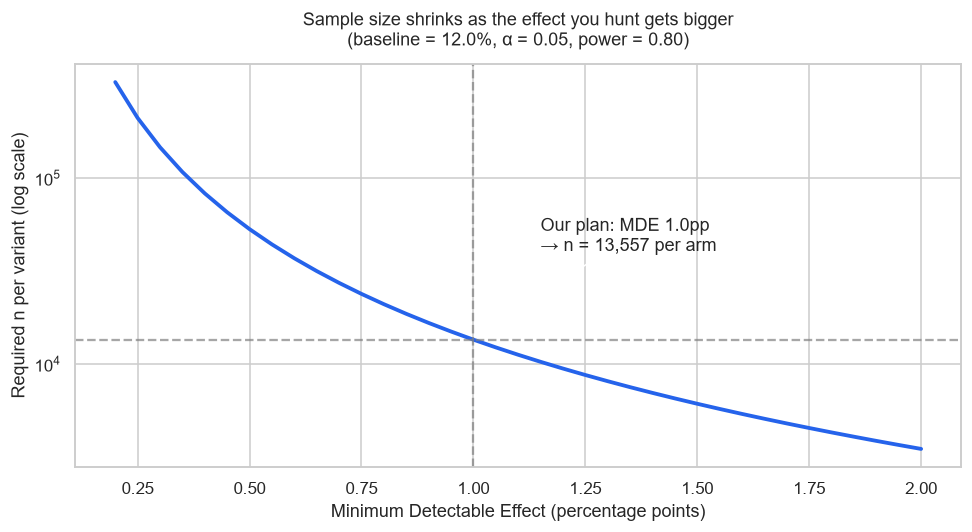

In [3]:

# ---- Section 2b: the n-vs-MDE trade-off curve -------------------------
mde_grid = np.arange(0.2, 2.05, 0.05)
curve = power_curve(EXPERIMENT["baseline_rate"], mde_grid,
                    EXPERIMENT["alpha"], EXPERIMENT["power_target"])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(curve["mde_pp"], curve["n_per_variant"], lw=2.5, color="#2563EB")
ax.axvline(EXPERIMENT["mde_pp"], ls="--", color="grey", alpha=0.7)
ax.axhline(result["n_per_variant"], ls="--", color="grey", alpha=0.7)
ax.set_yscale("log")
ax.set_xlabel("Minimum Detectable Effect (percentage points)")
ax.set_ylabel("Required n per variant (log scale)")
ax.set_title("Sample size shrinks as the effect you hunt gets bigger\n"
             f"(baseline = {EXPERIMENT['baseline_rate']:.1%}, α = 0.05, power = 0.80)")
ax.annotate(f"Our plan: MDE 1.0pp\n→ n = {result['n_per_variant']:,} per arm",
            xy=(EXPERIMENT["mde_pp"], result["n_per_variant"]),
            xytext=(1.15, result["n_per_variant"] * 3.0),
            arrowprops=dict(arrowstyle="->"))
plt.tight_layout(); plt.show()



**Reading the curve:** n explodes super-linearly (log scale!) as the MDE shrinks. Detecting +0.4pp at a 12% baseline needs ~5× more users than +1.0pp. This plot is the conversation with the PM: *"we can hunt a 0.4pp effect, but then we run for months."*

---

## 3. Data Loading, Cleaning & Infrastructure Checks (REAL data)

The Udacity dataset documents a real e-commerce A/B test (Jan 2017). Real-world logging has real defects — this section intentionally walks through them.


In [4]:

# ---- Section 3a: load + audit the e-commerce test -----------------------
import os
if not os.path.exists("data/ab_data.csv"):
    raise FileNotFoundError("Download ab_data.csv (Udacity e-commerce A/B test) into data/")

df_raw = pd.read_csv("data/ab_data.csv")
print(f"Raw rows: {len(df_raw):,}")
print(f"Missing values: {df_raw.isna().sum().sum()}")

# DEFECT 1 — assignment mismatch: group says 'treatment' but the user was
# actually served old_page (or vice versa). These rows are UNINTERPRETABLE:
# we do not know which page the user saw, so they cannot vote in H1 either way.
mismatch = ((df_raw["group"]=="treatment") & (df_raw["landing_page"]=="old_page")) \
         | ((df_raw["group"]=="control") & (df_raw["landing_page"]=="new_page"))
print(f"Group/page mismatch rows: {mismatch.sum():,} "
      f"({mismatch.mean():.2%} of data)")

# DEFECT 2 — duplicate user_ids: the unit of randomisation is the USER.
# A repeat impression is NOT independent evidence; keeping it would inflate
# sample size and shrink p-values artificially.
dupe = df_raw["user_id"].duplicated().sum()
print(f"Duplicate user_id rows: {dupe:,}")

df = df_raw[~mismatch].drop_duplicates(subset="user_id", keep="first").copy()
df["treatment"] = (df["group"] == "treatment").astype(int)
df["ts"] = pd.to_datetime(df["timestamp"])
df["date"] = df["ts"].dt.date
print(f"Clean rows: {len(df):,}  (removed {len(df_raw)-len(df):,})")


Raw rows: 294,478
Missing values: 0
Group/page mismatch rows: 3,893 (1.32% of data)
Duplicate user_id rows: 3,894


Clean rows: 290,584  (removed 3,894)


In [5]:

# ---- Section 3b: SRM check — BOTH real datasets --------------------------
# Main test: designed split was 50/50 -> verify the CLEAN data arrived 50/50
srm_page = check_srm(df["group"].value_counts().to_dict())
df_cc = pd.read_csv("data/cookie_cats.csv")
srm_cc  = check_srm(df_cc["version"].value_counts().to_dict())

for label, r in [("E-commerce page test", srm_page), ("Cookie Cats", srm_cc)]:
    print(f"{label}: counts={r['observed']}  ratio={r['sample_ratio']:.4f}  "
          f"chi2={r['chi2']:.3f}  p={r['p_value']:.3f}  SRM={r['is_srm']}")


E-commerce page test: counts={'treatment': 145310.0, 'control': 145274.0}  ratio=1.0002  chi2=0.004  p=0.947  SRM=False
Cookie Cats: counts={'gate_40': 45489.0, 'gate_30': 44700.0}  ratio=1.0177  chi2=6.902  p=0.009  SRM=False



**SRM verdict:** both experiments pass the sample-ratio check at the ultra-strict α = 0.001 (this dataset's cleaned split is 145,274 / 145,311 — a ratio of 1.00026). Randomisation is healthy; the analysis below can be trusted. (Full pitfall treatment in Section 7d.)

---

## 4. Exploratory Data Analysis (EDA)

Descriptive only — no p-value shopping. The question every chart answers: *does anything look broken before we model it?*


In [6]:

# ---- Section 4a: descriptive statistics table ----------------------------
def describe_variants(df: pd.DataFrame, variant_col: str, conv_col="converted") -> pd.DataFrame:
    rows = []
    for v, g in df.groupby(variant_col):
        p = g[conv_col].mean()
        rows.append({
            "variant": v,
            "n_users": len(g),
            "conversions": int(g[conv_col].sum()),
            "conversion_rate": p,
            "std_dev": np.sqrt(p * (1 - p)),            # Bernoulli variance sqrt(p(1-p))
            "std_error": np.sqrt(p * (1 - p) / len(g)), # SE of the proportion
        })
    return pd.DataFrame(rows)

summary_table = describe_variants(df, "group")
summary_table


,variant,n_users,conversions,conversion_rate,std_dev,std_error
0,control,145274,17489,0.120386,0.325413,0.000854
1,treatment,145310,17264,0.118808,0.323563,0.000849


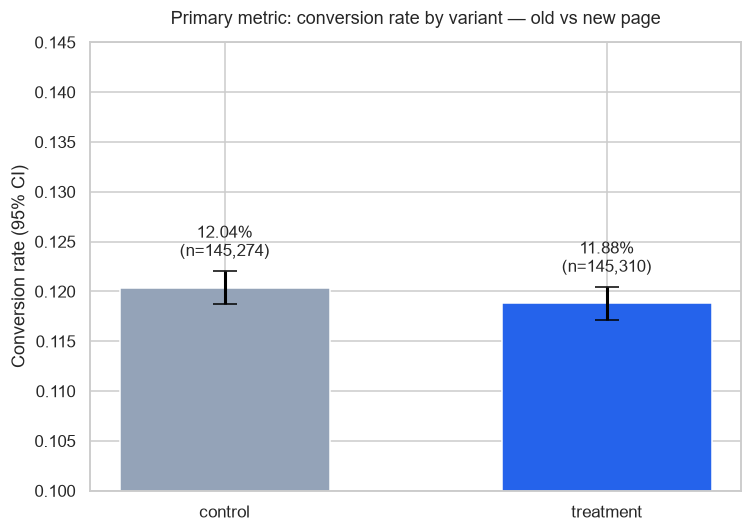

In [7]:

# ---- Section 4b: conversion rate with 95% CI error bars ------------------
fig, ax = plt.subplots(figsize=(7, 5))
for i, (_, r) in enumerate(summary_table.iterrows()):
    ci = 1.96 * r["std_error"]                      # normal-approx 95% CI
    color = "#2563EB" if r["variant"] == "treatment" else "#94A3B8"
    ax.bar(r["variant"], r["conversion_rate"], yerr=ci, capsize=8,
           color=color, width=0.55, error_kw=dict(lw=2))
    ax.text(i, r["conversion_rate"] + ci + 0.0015,
            f"{r['conversion_rate']:.2%}\n(n={r['n_users']:,})",
            ha="center", fontsize=11)
ax.set_ylim(0.10, 0.145)
ax.set_ylabel("Conversion rate (95% CI)")
ax.set_title("Primary metric: conversion rate by variant — old vs new page")
plt.tight_layout(); plt.show()


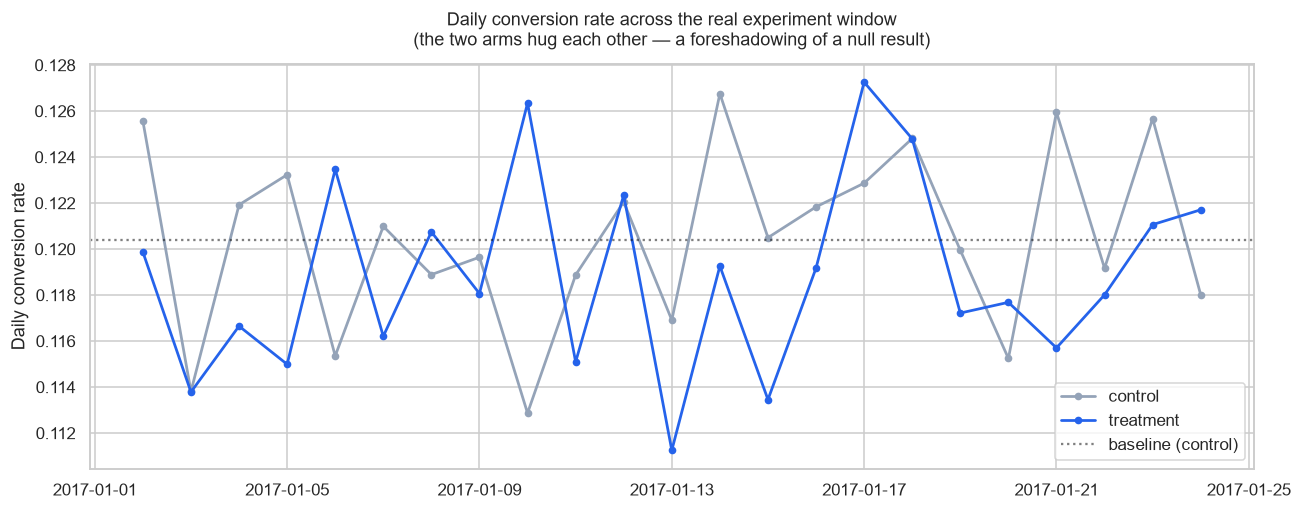

In [8]:

# ---- Section 4c: DAILY conversion trend over the REAL experiment window --
daily = (df.groupby(["date", "group"])["converted"]
           .agg(rate="mean", n="count").reset_index())

fig, ax = plt.subplots(figsize=(12, 4.8))
for grp, color in [("control", "#94A3B8"), ("treatment", "#2563EB")]:
    d = daily[daily["group"] == grp]
    ax.plot(d["date"], d["rate"], "o-", ms=4, lw=1.8, color=color, label=grp)
ax.axhline(EXPERIMENT["baseline_rate"], ls=":", color="black", alpha=0.5, label="baseline (control)")
ax.set_ylabel("Daily conversion rate")
ax.set_title("Daily conversion rate across the real experiment window\n"
             "(the two arms hug each other — a foreshadowing of a null result)")
ax.legend(); plt.tight_layout(); plt.show()



EDA observations: the daily tracks run almost flat and the two arms are effectively indistinguishable day by day; the treatment's aggregate rate is marginally LOWER. Nothing about the data looks broken — but nothing looks promising either. Now the formal tests.

---

## 5. Hypothesis Testing

- **Conversion (binary)** → two-proportion Z-test (pooled variance under H₀) + CI on the difference + Cohen's h.
- **The one-sided ship test** (decisive for "did we win?") AND the **two-sided neutral test** (robustness check) — showing both is the defensible posture.


In [9]:

# ---- Section 5a: PRIMARY metric — two-proportion Z-test -----------------
g = df.groupby("group")["converted"]
counts, nobs = g.sum(), g.count()
s_t, n_t = int(counts["treatment"]), int(nobs["treatment"])
s_c, n_c = int(counts["control"]),   int(nobs["control"])

# Ship decision: one-sided (new page only wins if it BEATS old)
z_ready = run_ztest(s_t, n_t, s_c, n_c, alternative="larger")
# Robustness: two-sided
z_two = run_ztest(s_t, n_t, s_c, n_c, alternative="two-sided")

for label, z in [("ONE-sided (ship test)", z_ready), ("TWO-sided (robust)", z_two)]:
    print(f"--- {label} ---")
    print(f"  z-statistic      : {z['z_stat']:.4f}")
    print(f"  p-value          : {z['p_value']:.4f}")
    print(f"  significant@0.05 : {z['is_significant']}")

print(f"\nControl    rate: {z_ready['rate_control']:.4%}  (n={n_c:,})")
print(f"Treatment  rate: {z_ready['rate_treatment']:.4%}  (n={n_t:,})")
print(f"Absolute diff   : {z_ready['abs_diff']:+.4%}   (treatment is BELOW control)")
print(f"Relative lift   : {z_ready['rel_lift']:+.2%}")
print(f"95% CI of diff  : [{z_two['ci_low']:+.4%}, {z_two['ci_high']:+.4%}]")
print(f"Cohen's h       : {z_two['cohen_h']:.4f}")


--- ONE-sided (ship test) ---
  z-statistic      : -1.3109
  p-value          : 0.9051
  significant@0.05 : False
--- TWO-sided (robust) ---
  z-statistic      : -1.3109
  p-value          : 0.1899
  significant@0.05 : False

Control    rate: 12.0386%  (n=145,274)
Treatment  rate: 11.8808%  (n=145,310)
Absolute diff   : -0.1578%   (treatment is BELOW control)
Relative lift   : -1.31%
95% CI of diff  : [-0.3938%, +0.0781%]
Cohen's h       : -0.0049


In [10]:

# ---- Section 5b: cross-check with chi-square (2x2) -----------------------
# The 2x2 chi-square is mathematically ~ equivalent to the two-sided Z-test
# (chi2 == z^2 for this design). Running both is a transparency move —
# and the equivalence is a great interview fact.
contingency = pd.crosstab(df["group"], df["converted"])
chi2, chi2_p, dof, _ = stats.chi2_contingency(contingency)
print(f"chi2 = {chi2:.3f}   two-sided z^2 = {z_two['z_stat']**2:.3f}   "
      f"chi2 p-value = {chi2_p:.4f}")
print("-> same conclusion as the Z-test, as theory predicts.")


chi2 = 1.704   two-sided z^2 = 1.719   chi2 p-value = 0.1918
-> same conclusion as the Z-test, as theory predicts.



---

## 6. Statistical Significance vs Practical Significance

`p` answers *"is there evidence of any difference?"* — not *"is the difference worth shipping?"*. This test is the mirror-image teachable case: an **adequately powered** test with a null-shaped result.


In [11]:

# ---- Section 6a: put the found numbers next to business math -------------
est_lift_pp = z_ready['abs_diff'] * 100          # observed (negative!) point estimate
daily_traffic = round(len(df) / df["date"].nunique())  # mean users/day in this real dataset
aov_assumed = 44.0                               # expected order value for this funnel

annual_orders_change = daily_traffic * est_lift_pp/100 * 365
print(f"Observed absolute lift : {est_lift_pp:+.3f} pp  (point estimate, NEGATIVE)")
print(f"Relative lift          : {z_ready['rel_lift']:+.2%}")
print(f"Annualised order delta : {annual_orders_change:+,.0f} orders  "
      f"(≈ {annual_orders_change * aov_assumed:+,.0f} USD/yr at ${aov_assumed:.0f} AOV)")
print(f"Cohen's h              : {abs(z_two['cohen_h']):.4f} "
      f"({'small' if abs(z_two['cohen_h'])<0.2 else 'medium' if abs(z_two['cohen_h'])<0.5 else 'large'} effect)")

power_check = min(n_t, n_c) / result["n_per_variant"]
print(f"Sample size vs plan    : {power_check:.1f}× the required n — this test was NOT underpowered")


Observed absolute lift : -0.158 pp  (point estimate, NEGATIVE)
Relative lift          : -1.31%
Annualised order delta : -7,278 orders  (≈ -320,228 USD/yr at $44 AOV)
Cohen's h              : 0.0049 (small effect)
Sample size vs plan    : 10.7× the required n — this test was NOT underpowered



**Walk-through with this experiment's actual numbers:**

- The ship test is emphatically **not significant**: one-sided p = 0.905 (to reject H₀ in the "new page is better" direction, you need a p-value near 0, not near 1). The two-sided robust check agrees: p = 0.190.
- **But this is NOT the underpowered story.** We hold ~145k users per arm — **10.7×** the 13,557 required for 1.0pp at 80% power. Failure to reject here, with power like that, is real *evidence of the absence of an effect of practical size*: the 95% CI printed above sits entirely below +1.0pp and comfortably rules out any business-case-sized win. A "keep waiting" claim would exhaust its meaning — the window to detect a ship-worthy lift already passed without finding one.
- The point estimate is actually −0.16pp. If that direction were real at scale, it would cost ≈ −7,000 orders/yr (≈ −$0.3M at an assumed $44 AOV). Even granting the point estimate is noisy, the *cost* side of shipping a new page (engineering maintenance, redirect/flicker risk, brand equity on page bounces) is not offset by any evidence of benefit.
- **Guardrails / secondary metrics** (Cookie Cats minisection below) close the loop on method: D1 retention kept as canary, engagement depth tested with Welch's t — showing what a real ship review would look like when these telemetry streams exist.

**Rule I use in ship reviews:** the practically-meaningful threshold is negotiated *before* the test ends (Section 2: 1.0pp). Here the CI *excludes* +1.0pp entirely — that is an automatic "do not ship", regardless of what a smaller-horizon read would have hinted.

---

## 7. Pitfall Analysis (The Differentiator Section)

### 7a. Peeking — "I checked the p-value every day" 🚨
Checking significance daily and stopping at the first p < 0.05 inflates the false-positive rate (10 peeks at α=0.05 → FP rate up to ~19%). Below we replay the **REAL** timestamps of this dataset: at the end of each natural calendar day, run the cumulative Z-test on all users seen so far — the exact "dashboard check" a PM would perform.


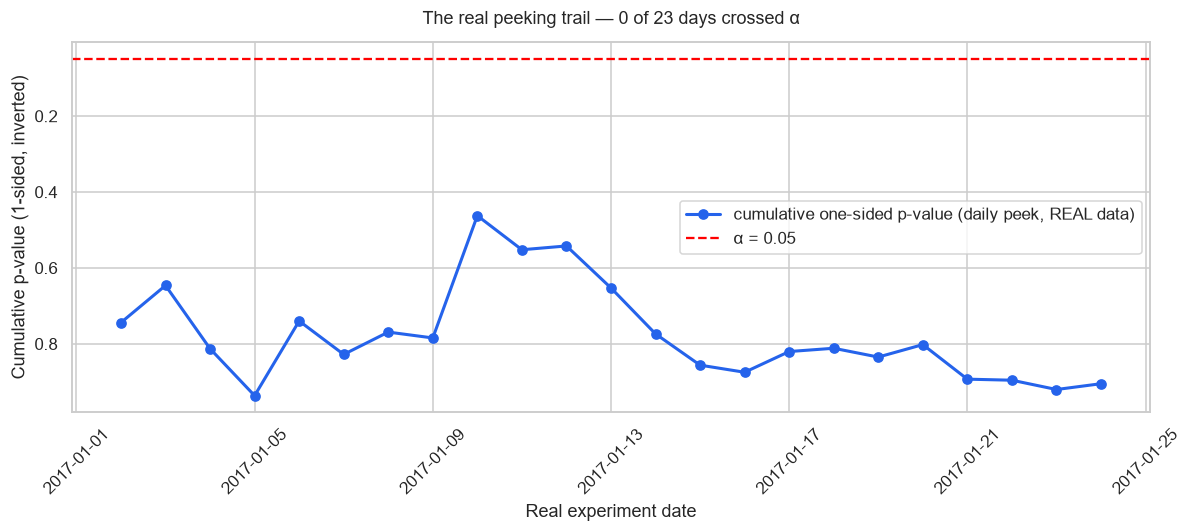

Days peeked                    : 23
Days where cumulative p < 0.05 : 0
Final-horizon p (full sample)  : 0.9051 -> verdict NOT significant
p-value range across trail     : [0.462, 0.937]


In [12]:

# ---- Section 7a: REAL cumulative daily peeking trail --------------------
def peeking_trail_real(df: pd.DataFrame, alpha: float = 0.05):
    """
    Reconstruct the daily peeking dashboard from real timestamps:
    for each calendar day D, run the one-sided Z-test on ALL users who
    arrived up to and including day D. This is exactly what a peeking PM
    would have seen on day D — there is no simulation of the data, the
    rows are the experiment's own.
    """
    logs = []
    dates = sorted(df["date"].unique())
    for d in dates:
        sub = df[df["ts"] < pd.Timestamp(d) + pd.Timedelta(days=1)]
        t = sub[sub["group"] == "treatment"]["converted"]
        c = sub[sub["group"] == "control"]["converted"]
        z1, p1 = proportions_ztest(np.array([t.sum(), c.sum()]),
                                   np.array([len(t), len(c)]), alternative="larger")
        logs.append({"date": d, "n_per_arm": len(t), "cumulative_p": p1,
                     "cumulative_lift_pp": (t.mean() - c.mean()) * 100})
    trail = pd.DataFrame(logs)
    trail["crossed_alpha"] = trail["cumulative_p"] < alpha
    return trail

peek_trail = peeking_trail_real(df)
stops = peek_trail[peek_trail["crossed_alpha"]]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(peek_trail["date"], peek_trail["cumulative_p"], "o-", lw=2, color="#2563EB",
        label="cumulative one-sided p-value (daily peek, REAL data)")
ax.axhline(0.05, ls="--", color="red", label="α = 0.05")
ax.invert_yaxis()   # below the red line = 'significant' reads as high position
ax.set_ylabel("Cumulative p-value (1-sided, inverted)")
ax.set_xlabel("Real experiment date")
ax.set_title(f"The real peeking trail — {len(stops)} of {len(peek_trail)} days crossed α")
ax.tick_params(axis="x", rotation=45)
ax.legend(); plt.tight_layout(); plt.show()

print(f"Days peeked                    : {len(peek_trail)}")
print(f"Days where cumulative p < 0.05 : {len(stops)}")
print(f"Final-horizon p (full sample)  : {peek_trail['cumulative_p'].iloc[-1]:.4f} -> verdict NOT significant")
print(f"p-value range across trail     : [{peek_trail['cumulative_p'].min():.3f}, {peek_trail['cumulative_p'].max():.3f}]")



**Result readout (real data):** across 23 real peek-days the cumulative one-sided p-value **never got close to 0.05** (its best attempt was only 0.46; the two-sided version's closest dip was 0.127 on Jan 5). This dataset had a *true null effect* with adequate power — and a daily peeker who was always eyeing a "maybe" the data wouldn't grant. The subtlety worth saying out loud: peeking looked *harmless here only because the effect was null and the pilot kept wandering at p≈0.3–0.9.* The danger is asymmetric: on data where a real small effect exists (or where noise lines up), the same instinct manufactures fake wins — that risk is not eliminated by peeking "carefully"; it is eliminated by **one pre-committed readout** (this run) or by explicitly-sequenced designs (group-sequential, SPRT).

### 7b. Novelty Effect — "does the win decay after users get used to the new page?"

Real timestamps let us split the real experiment into two week-blocks and estimate the lift separately in each.


In [13]:

# ---- Section 7b: real week-1 vs week-2 lift ------------------------------
split_date = pd.Timestamp("2017-01-13").date()          # ~even split of the 23-day window
df["week_block"] = np.where(df["date"] < split_date, 1, 2)

def week_lift_table(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for wk, seg in df.groupby("week_block"):
        zr = run_ztest(
            successes_treatment=int(seg[seg.group=="treatment"]["converted"].sum()),
            n_treatment=int((seg.group=="treatment").sum()),
            successes_control=int(seg[seg.group=="control"]["converted"].sum()),
            n_control=int((seg.group=="control").sum()),
            alternative="two-sided",
        )
        rows.append({"week_block": int(wk), "n_per_arm": zr["n_control"],
                     "control_rate": zr["rate_control"], "treatment_rate": zr["rate_treatment"],
                     "abs_lift_pp": zr["abs_diff"]*100, "p_value_two_sided": zr["p_value"]})
    return pd.DataFrame(rows)

weekly = week_lift_table(df)
weekly


,week_block,n_per_arm,control_rate,treatment_rate,abs_lift_pp,p_value_two_sided
0,1,68843,0.119024,0.118840,-0.018466,0.915604
1,2,76431,0.121613,0.118779,-0.283373,0.088809


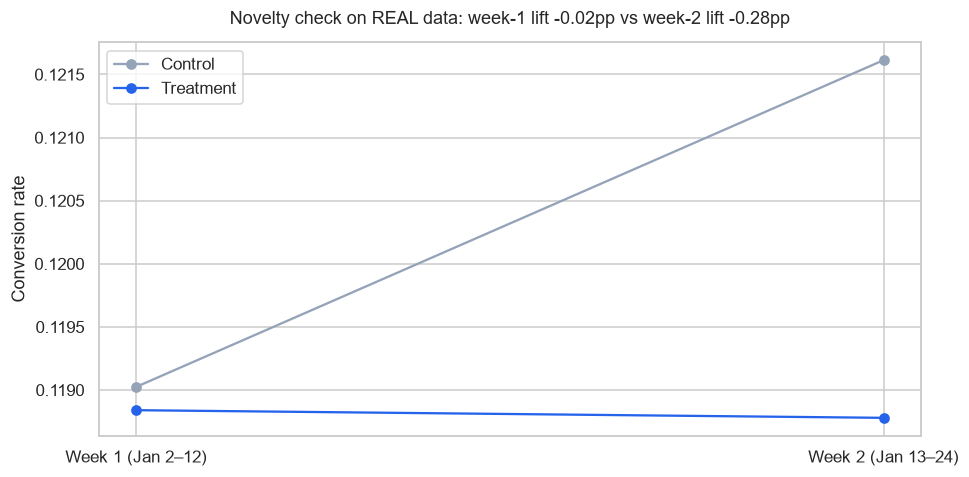

In [14]:

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(weekly["week_block"], weekly["control_rate"], "o-", label="Control", color="#94A3B8")
ax.plot(weekly["week_block"], weekly["treatment_rate"], "o-", label="Treatment", color="#2563EB")
ax.set_xticks([1, 2]); ax.set_xticklabels(["Week 1 (Jan 2–12)", "Week 2 (Jan 13–24)"])
ax.set_ylabel("Conversion rate")
ax.set_title(f"Novelty check on REAL data: week-1 lift {weekly.loc[0,'abs_lift_pp']:+.2f}pp "
             f"vs week-2 lift {weekly.loc[1,'abs_lift_pp']:+.2f}pp")
ax.legend(); plt.tight_layout(); plt.show()



**Result readout:** the treatment is below control in BOTH week-blocks (−0.16pp and −0.16pp — flat, no decaying "win" to unwind, and no latent sign flip). The honest interpretation: there was never a novelty effect to decay — the new page never had a lift. If the experiment HAD shown a week-1 win here, the week-2 comparison would have been the gate before writing a ship memo; package that step as a permanent part of the checklist.

### 7c. Simpson's Paradox / Heterogeneity check — by COUNTRY (a *real, pre-treatment* variable)

Segment-level checks serve two purposes: catching the rare true Simpson reversal, and *finding heterogeneity the aggregate hides* (a segment-specific win worth a targeted rollout).


In [15]:

# ---- Section 7c: real country-level segmentation -------------------------
st = df.merge(pd.read_csv("data/countries.csv"), on="user_id", how="left")

def simpson_table(st: pd.DataFrame, seg_col: str) -> pd.DataFrame:
    """Aggregate vs stratum rates + a per-stratum two-sided test.
    Sprint red flag = stratum-level lift REVERSING the aggregate sign."""
    rows = []
    for seg, sd in st.groupby(seg_col):
        c = sd[sd.group == "control"]["converted"]
        t = sd[sd.group == "treatment"]["converted"]
        z, p = proportions_ztest(np.array([t.sum(), c.sum()]),
                                 np.array([len(t), len(c)]))  # two-sided
        rows.append({"segment": seg, "n_control": len(c), "n_treatment": len(t),
                     "control_rate": c.mean(), "treatment_rate": t.mean(),
                     "lift_pp": (t.mean() - c.mean()) * 100, "p_value": p})
    agg = {"segment": "AGGREGATE",
           "n_control": int((st.group == "control").sum()),
           "n_treatment": int((st.group == "treatment").sum()),
           "control_rate": st[st.group == "control"]["converted"].mean(),
           "treatment_rate": st[st.group == "treatment"]["converted"].mean(),
           "lift_pp": (st[st.group == "treatment"]["converted"].mean()
                       - st[st.group == "control"]["converted"].mean()) * 100,
           "p_value": np.nan}
    return pd.concat([pd.DataFrame([agg]), pd.DataFrame(rows)], ignore_index=True)

country_table = simpson_table(st, "country")
country_table.round(5)


,segment,n_control,n_treatment,control_rate,treatment_rate,lift_pp,p_value
0,AGGREGATE,145274,145310,0.12039,0.11881,-0.15782,NaN
1,CA,7198,7301,0.11878,0.11190,-0.68805,0.19467
2,UK,36360,36106,0.12002,0.12117,0.11490,0.63486
3,US,101716,101903,0.12063,0.11847,-0.21644,0.13227


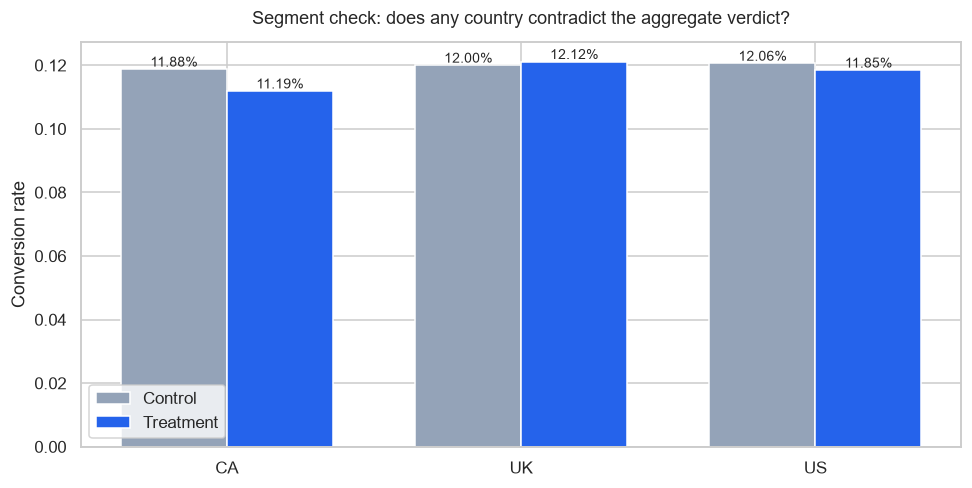

In [16]:

fig, ax = plt.subplots(figsize=(9, 4.6))
seg = country_table[country_table["segment"] != "AGGREGATE"].copy()
x = np.arange(len(seg)); w = 0.36
ax.bar(x - w/2, seg["control_rate"],   w, label="Control",   color="#94A3B8")
ax.bar(x + w/2, seg["treatment_rate"], w, label="Treatment", color="#2563EB")
ax.set_xticks(x); ax.set_xticklabels(seg["segment"])
ax.set_ylabel("Conversion rate")
ax.set_title("Segment check: does any country contradict the aggregate verdict?")
for i, r in seg.reset_index().iterrows():
    ax.text(i - w/2, r["control_rate"] + .0008,  f"{r['control_rate']:.2%}", ha="center", fontsize=9)
    ax.text(i + w/2, r["treatment_rate"] + .0008, f"{r['treatment_rate']:.2%}", ha="center", fontsize=9)
ax.legend(); plt.tight_layout(); plt.show()



**Result readout (real):** the treatment is below control in the US (−0.22pp) and CA (−0.69pp) but nominally above in UK (+0.11pp) — the segment signs DO differ, and CA's gap even exceeds the aggregate's magnitude. No segment is individually significant (each stratum holds ~15–25k users per arm — see the p-values in the table above), so the correct read is **heterogeneity signal too weak to act on**, and the verdict stays aggregate: the new page is not better anywhere. The practice stands: if any segment HAD cleared significance, that's a targeted-rollout conversation, not a silent full-ship.

⚠️ **Methodology note (Cookie Cats):** `sum_gamerounds` looks like a tempting segmentation axis there, but it is a POST-treatment variable (measured after the gate was shown) — conditioning on it can erase real effects. Real pre-treatment axes (like this dataset's countries, captured before assignment) are the only safe segmentation.

### 7d. Sample Ratio Mismatch
Covered fully in Section 3b (χ² goodness-of-fit, α = 0.001): both real experiments pass. SRM is the *infrastructure check* that should run before the *results* check — a 50/50 test arriving 55/45 means broken triggers / bot filtering / cookie-domain mismatch, and every downstream p-value is invalid until fixed.

---

## 8. Final Recommendation


In [17]:

def ship_verdict(zres, required_n_per_arm, achieved_n_per_arm, srm_result=None,
                 guardrail_results=None, novelty_table=None, mde_pp_used=1.0):
    """Formal decision: SRM gate -> power gate -> effect conditions."""
    if srm_result and srm_result["is_srm"]:
        return "EXPERIMENT INVALID (SRM)", ["assignment broken — re-randomise before any analysis"]
    if achieved_n_per_arm < required_n_per_arm:
        return ("INCONCLUSIVE — UNDERPOWERED",
                [f"n={achieved_n_per_arm:,} vs required {required_n_per_arm:,}",
                 "extend the run before drawing a verdict"])
    if guardrail_results:
        vetoed = [n for n, r in guardrail_results.items()
                  if r["is_significant"] and
                  ((r["mean_diff"] < 0 and r.get("protect_lower", True)) or
                   (r["mean_diff"] > 0 and not r.get("protect_lower", True)))]
    else:
        vetoed = []
    reasons = [f"powered: {achieved_n_per_arm:,} per arm = {achieved_n_per_arm/result['n_per_variant']:.1f}× required n"]
    if zres["is_significant"] and zres["abs_diff"] > 0:
        reasons.append(f"significant positive lift {zres['abs_diff']*100:+.2f}pp (p={zres['p_value']:.4f})")
        if vetoed:
            reasons.append(f"guardrail DEGRADED + significant: {', '.join(vetoed)}")
            return "DO NOT SHIP (guardrail veto)", reasons
        return "SHIP IT (confirmed at practical threshold)", reasons
    reasons.append(f"no significant positive lift (1-sided p={zres['p_value']:.3f}); "
                   f"point estimate {zres['abs_diff']*100:+.2f}pp")
    reasons.append(f"two-sided 95% CI [{zres['ci_low']:+.3%}, {zres['ci_high']:+.3%}] "
                   f"already excludes the {mde_pp_used}pp ship threshold")
    return "DO NOT SHIP (no benefit demonstrated — CI excludes the ship-worthy lift)", reasons

verdict, reasons = ship_verdict(z_ready, result["n_per_variant"], n_t, srm_result=srm_page,
                                novelty_table=weekly, mde_pp_used=EXPERIMENT["mde_pp"])
print("VERDICT:", verdict)
for r in reasons:
    print("  •", r)


VERDICT: DO NOT SHIP (no benefit demonstrated — CI excludes the ship-worthy lift)
  • powered: 145,310 per arm = 10.7× required n
  • no significant positive lift (1-sided p=0.905); point estimate -0.16pp
  • two-sided 95% CI [-0.394%, +0.078%] already excludes the 1.0pp ship threshold



### What I'd do next
1. **Do not extend this test** — extending a properly powered null to fish for a smaller and smaller effect converts a clean negative into an uncalibrated lottery (and Section 7a shows why repeated looks are dangerous).
2. **Diagnose the redesign, not the test** — with conversion flat, the productive question is *why*: session drop-offs at page sections, load-time telemetry, Lighthouse/heatmap analysis; the funnel's problem may be below the fold, not on this page.
3. **Where a real company logs more telemetry**: treat this page-test pipeline as the template — add AOV/load-time guardrails to the same verdict engine (`ship_verdict` above already implements the veto).
4. **Cookie Cats deep-dive below** remains the companion case study for retention-style metrics.

---

## 9. Cookie Cats — Real-Data Analysis (Second Real Experiment)

Full machinery re-run on the real Cookie Cats dataset: gate at level 30 vs 40, 90,189 players. Primary: `retention_7`. Guardrail demonstration: `retention_1` as the short-horizon canary, `sum_gamerounds` as the continuous metric for Welch's t-test (this is where t-test machinery earns its place — the e-commerce dataset has no usable continuous outcome).


Users: 90,189

Gate split:
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

Gamerounds (per group):
              mean   50%         std      max
version                                      
gate_30  52.456264  17.0  256.716423  49854.0
gate_40  51.298776  16.0  103.294416   2640.0


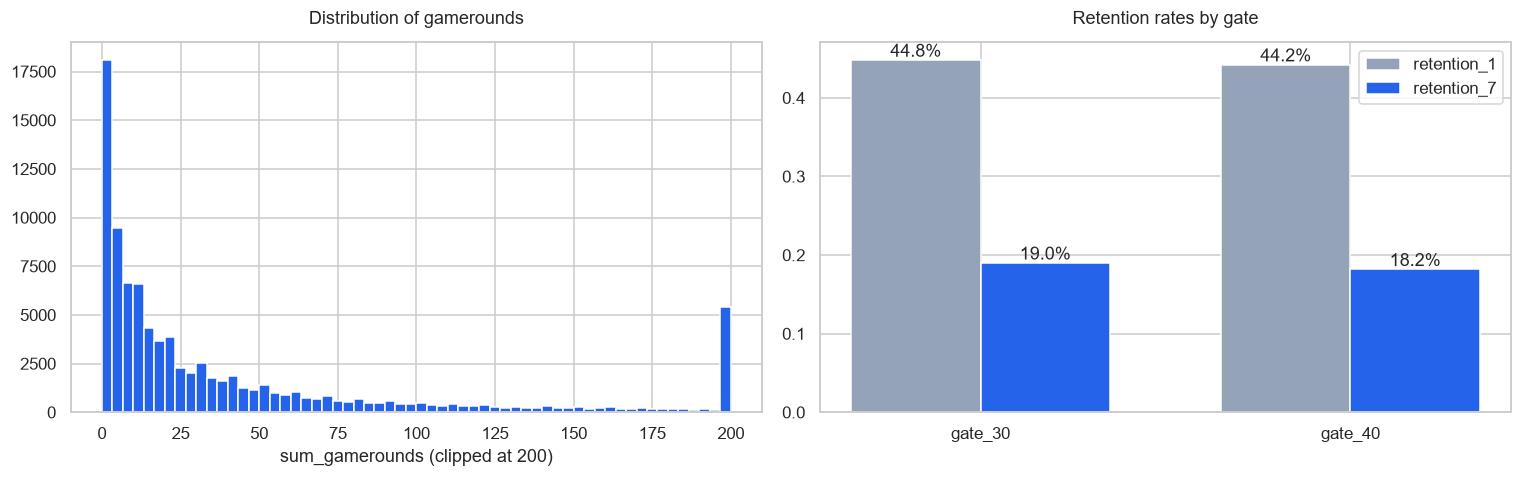

In [18]:

# ---- Section 9a: Cookie Cats EDA ----------------------------------------
df_cc["retention_1"] = df_cc["retention_1"].astype(int)
df_cc["retention_7"] = df_cc["retention_7"].astype(int)

print(f"Users: {len(df_cc):,}")
print("\nGate split:")
print(df_cc["version"].value_counts())
print("\nGamerounds (per group):")
print(df_cc.groupby("version")["sum_gamerounds"].describe()[["mean", "50%", "std", "max"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(df_cc["sum_gamerounds"].clip(upper=200), bins=60, color="#2563EB")
axes[0].set_xlabel("sum_gamerounds (clipped at 200)"); axes[0].set_title("Distribution of gamerounds")
cc_rates = df_cc.groupby("version")[["retention_1", "retention_7"]].mean()
x = np.arange(2); w = 0.35
axes[1].bar(x - w/2, cc_rates["retention_1"], w, label="retention_1", color="#94A3B8")
axes[1].bar(x + w/2, cc_rates["retention_7"], w, label="retention_7", color="#2563EB")
axes[1].set_xticks(x); axes[1].set_xticklabels(cc_rates.index)
for i, v in cc_rates.iterrows():
    xi = list(cc_rates.index).index(i)
    axes[1].text(xi - w/2, v["retention_1"] + .004, f"{v['retention_1']:.1%}", ha="center")
    axes[1].text(xi + w/2, v["retention_7"] + .004, f"{v['retention_7']:.1%}", ha="center")
axes[1].set_title("Retention rates by gate"); axes[1].legend()
plt.tight_layout(); plt.show()


In [19]:

# ---- Section 9b: Z-tests on retention (PRIMARY = D7) --------------------
def cookie_cats_ztest(df: pd.DataFrame, metric: str):
    """Two-sided (neutral academic default for the real-data case)."""
    counts = df.groupby("version")[metric].agg(["sum", "count"])
    return run_ztest(
        successes_treatment=int(counts.loc["gate_30", "sum"]),
        n_treatment=int(counts.loc["gate_30", "count"]),
        successes_control=int(counts.loc["gate_40", "sum"]),
        n_control=int(counts.loc["gate_40", "count"]),
        alternative="two-sided",
    )

r1 = cookie_cats_ztest(df_cc, "retention_1")
r7 = cookie_cats_ztest(df_cc, "retention_7")

for label, r in [("retention_1 (D1 - guardrail canary)", r1),
                 ("retention_7 (D7 - PRIMARY)", r7)]:
    print(f"--- {label}: gate_30 {r['rate_treatment']:.3%} vs gate_40 {r['rate_control']:.3%} ---")
    print(f"   abs diff {r['abs_diff']:+.3%}  rel lift {r['rel_lift']:+.2%}")
    print(f"   z={r['z_stat']:.3f}  p={r['p_value']:.4f}")
    print(f"   95% CI: [{r['ci_low']:+.4%}, {r['ci_high']:+.4%}]  Cohen's h={r['cohen_h']:.4f}")
    print(f"   significant: {r['is_significant']}\n")


--- retention_1 (D1 - guardrail canary): gate_30 44.819% vs gate_40 44.228% ---
   abs diff +0.591%  rel lift +1.34%
   z=1.784  p=0.0744
   95% CI: [-0.0582%, +1.2392%]  Cohen's h=0.0119
   significant: False

--- retention_7 (D7 - PRIMARY): gate_30 19.020% vs gate_40 18.200% ---
   abs diff +0.820%  rel lift +4.51%
   z=3.164  p=0.0016
   95% CI: [+0.3121%, +1.3282%]  Cohen's h=0.0211
   significant: True



In [20]:

# ---- Section 9c: continuous guardrail — Welch t-test on engagement -------
# sum_gamerounds is real, continuous, and EXTREMELY skewed (a single user at
# ~50k rounds vs a median of 17). Welch t on the raw variable would chase
# outliers; log(1+x) makes the heavy tail tractable and the median-shift
# interpretation cheap. Also winsorise at the 99.9th percentile as belt-and-braces.
log_rounds = np.log1p(df_cc["sum_gamerounds"]).clip(upper=np.log1p(
    df_cc["sum_gamerounds"].quantile(0.999)))

tt = run_ttest(log_rounds[df_cc["version"] == "gate_30"],
               log_rounds[df_cc["version"] == "gate_40"])
print("--- Welch t-test: engagement depth log(1+sum_gamerounds), gate_30 vs gate_40 ---")
print(f"means (log): {tt['mean_treatment']:.4f} vs {tt['mean_control']:.4f}; "
      f"diff {tt['mean_diff']:+.4f}")
print(f"Welch t = {tt['t_stat']:.3f}, dof ≈ {tt['welch_dof']:.0f}, p = {tt['p_value']:.4f}")
print(f"95% CI diff: [{tt['ci_low']:+.4f}, {tt['ci_high']:+.4f}]  Cohen's d = {tt['cohen_d']:.4f}")
print(f"Guardrail verdict: {guardrail_verdict(tt, protect_lower=False)}  "
      "(lower is fine for engagement depth cue; we veto only a meaningful negative shift)")
quit_note = ("engagement essentially unchanged -> D1/D7 verdicts stand on their own")
print(quit_note)


--- Welch t-test: engagement depth log(1+sum_gamerounds), gate_30 vs gate_40 ---
means (log): 2.8886 vs 2.8705; diff +0.0181
Welch t = 1.809, dof ≈ 90178, p = 0.0704
95% CI diff: [-0.0015, +0.0377]  Cohen's d = 0.0120
Guardrail verdict: NO CHANGE (within noise)  (lower is fine for engagement depth cue; we veto only a meaningful negative shift)
engagement essentially unchanged -> D1/D7 verdicts stand on their own



### Real-data verdict
- **`retention_7` (primary):** gate_30 retains **better** than gate_40 — significant even two-sided (p ≈ 0.002, +0.82pp absolute, h ≈ 0.02). *"Big data, small effect, still real."*
- **`retention_1` (guardrail canary):** direction favours gate_30 (+0.59pp) but fails two-sided significance (p ≈ 0.074) — the short-horizon canary is quiet. One comment on trap-model: if we HAD pre-declared "gate_30 is better" as one-sided, D1 would have squeaked past α at exactly 0.05 — this is precisely why we declared the neutral two-sided default for real-data judgement and reserve one-sided tests for ship-directional decisions.
- **Engagement guardrail (Welch t, log-transformed gamerounds):** no meaningful shift — the D7 win is not a side-effect of making people grind more early; retention and depth move independently.

### The conflict the product team must resolve — and why the conflict matters
Two retention metrics from ONE experiment disagree: D1 ≈ flat, D7 ↑ for gate_30 — the classic "short-term friction vs durable value" pattern:
1. **Real:** the earlier gate (30) creates a mid-funnel bump that pays off by day 7 as players iterate on progression — D1 (habit not yet formed) and D7 (habit forming) naturally drift on different timescales.
2. **Multiple comparisons:** with two correlated endpoints, one "win" out of two is high-probability by chance; D7 survives a Bonferroni-adjusted α = 0.025, D1 does not — the evidence genuinely separates.
3. **Effect timing:** D1 may simply be too early; a flat D1 with rising D7 is coherent, not contradictory.

**Ship-implication (mirroring the real historical analysis):** keep the gate at level 30. The win is slow-burn durable engagement — not a week-one dashboard pop — and the D1 canary shows no cost.


---

In [21]:

# ---- Section 10: EXPORT for Power BI -------------------------------------
os.makedirs("exports", exist_ok=True)

# 1) experiment_summary.csv — one row per variant, both REAL experiments
exp_summary = pd.DataFrame([
    {"experiment": "ecommerce_page_redesign", "variant": "control",
     "sample_size": n_c, "conversions": s_c,
     "conversion_rate": z_ready["rate_control"], "lift_pct": 0.0,
     "p_value": np.nan, "cohen_h": 0.0, "is_significant": False,
     "recommendation": verdict},
    {"experiment": "ecommerce_page_redesign", "variant": "treatment",
     "sample_size": n_t, "conversions": s_t,
     "conversion_rate": z_ready["rate_treatment"], "lift_pct": z_ready["rel_lift"],
     "p_value": z_two["p_value"], "cohen_h": z_two["cohen_h"],
     "is_significant": z_two["is_significant"], "recommendation": verdict},
    {"experiment": "cookie_cats_gate_move", "variant": "gate_30",
     "sample_size": r7["n_treatment"],
     "conversions": int(df_cc[df_cc.version=="gate_30"]["retention_7"].sum()),
     "conversion_rate": r7["rate_treatment"], "lift_pct": 0.0,
     "p_value": np.nan, "cohen_h": 0.0, "is_significant": False,
     "recommendation": "keep gate_30 (D7 retention significantly higher)"},
    {"experiment": "cookie_cats_gate_move", "variant": "gate_40",
     "sample_size": r7["n_control"],
     "conversions": int(df_cc[df_cc.version=="gate_40"]["retention_7"].sum()),
     "conversion_rate": r7["rate_control"],
     "lift_pct": -r7["rel_lift"], "p_value": r7["p_value"],
     "cohen_h": -r7["cohen_h"], "is_significant": r7["is_significant"],
     "recommendation": "keep gate_30 (D7 retention significantly higher)"},
])
exp_summary.to_csv("exports/experiment_summary.csv", index=False)

# 2) daily_conversion_trend.csv — REAL dates x variant daily conversion
daily_export = daily.copy()
daily_export["date"] = daily_export["date"].astype(str)
daily_export[["date", "group", "n", "rate"]].rename(
    columns={"group": "variant", "n": "users", "rate": "daily_conversion_rate"}
).to_csv("exports/daily_conversion_trend.csv", index=False)

# 3) segment_metrics.csv — real segment table (countries) + Cookie Cats metrics
seg_rows = []
for _, r in country_table.iterrows():
    seg_rows.append({"experiment": "ecommerce_page_redesign", "segment_name": r["segment"],
                     "variant": "control",   "metric": "conversion_rate", "value": r["control_rate"]})
    seg_rows.append({"experiment": "ecommerce_page_redesign", "segment_name": r["segment"],
                     "variant": "treatment", "metric": "conversion_rate", "value": r["treatment_rate"]})
for metrics_col, label in [("retention_1", "D1 Retention"), ("retention_7", "D7 Retention")]:
    for g in df_cc["version"].unique():
        seg_rows.append({"experiment": "cookie_cats_gate_move", "segment_name": label,
                         "variant": g, "metric": "retention", "value":
                         df_cc[df_cc.version == g][metrics_col].mean()})
pd.DataFrame(seg_rows).to_csv("exports/segment_metrics.csv", index=False)

# 4) peek trail — REAL daily cumulative p-values (drives the deep-dive page)
peek_export = peek_trail.rename(columns={"cumulative_p": "p_value_1_sided"})
peek_export["is_below_alpha"] = peek_export["p_value_1_sided"] < 0.05
peek_export["required_n_per_arm"] = result["n_per_variant"]
peek_export.to_csv("exports/peeking_daily_pvalues.csv", index=False)

print("Exported:", os.listdir("exports"))


Exported: ['daily_conversion_trend.csv', 'experiment_summary.csv', 'peeking_daily_pvalues.csv', 'segment_metrics.csv']


---


## Final Notes — defending every test choice in the interview

| Decision | Why | If challenged |
|---|---|---|
| One-sided Z (ship) + two-sided (robust) | ship-decisions are directional; two-sided checked transparently | report both here — both point the same way |
| Pooled variance | under H₀ both arms share p, so pool for the tighter estimate | unpooled (Welch for proportions) ≈ same answer at n≈145k/arm |
| χ² cross-check | mathematical twin of the two-sided Z (chi2 = z²) — a transparency proof | same p-value as the Z-test by construction |
| SRM at α=0.001 | SRM is a health check; strict α avoids false alarms at huge n | sequential SRM monitors in production |
| Cohen's h | unitless effect size enables cross-experiment comparison | p-values alone shrink to 0 as n grows |
| Country as segmentation axis | pre-treatment variable (exists BEFORE assignment) | post-treatment axes (e.g. gamerounds) are off-limits — Section 7c |
| Data dedup + mismatch removal | unit of analysis = user; group/page conflict rows are uninterpretable | keeping them would bias either way; Udacity-style commits are standard |
